# Prueba de los modelos nuevos · Rueda de prensa del Consejo de Ministros (13/10/2026)

Este notebook ejecuta sobre la rueda de prensa:

1. **Script 1**: cortes de plano (PySceneDetect)
2. **Script 2**: detección y seguimiento de personas (YOLO11 + ByteTrack)
3. **Primeras métricas**: tiempo en pantalla, tamaño y centralidad por persona (todavía sin género ni audio)

**Antes de empezar**, en la **misma carpeta que este notebook** (o en una subcarpeta `videos/`) tienen que estar:
- los dos scripts: cualquier `.py` que empiece por `01` y por `02`
- el vídeo `consejo_131026.mp4`, o sus dos trozos `consejo_131026.f401.mp4` + `consejo_131026.f251-3.webm`

Fuente: *Origen de los datos: sitio web de lamoncloa.gob.es. Ministerio de la Presidencia.* Vídeo: https://www.youtube.com/watch?v=_MtccDhRCi0

## 0. Configuración y comprobación del vídeo

In [8]:
import os
import subprocess
from pathlib import Path

import cv2

BASE = Path.cwd()   # la carpeta donde está ESTE notebook
print("Carpeta de trabajo:", BASE)

# Scripts: buscamos cualquier .py que empiece por 01 y por 02 (da igual espacios, tildes o mayúsculas)
def buscar_script(prefijo):
    encontrados = sorted(BASE.glob(prefijo + "*.py"))
    return encontrados[0] if encontrados else None

SCRIPT1 = buscar_script("01")
SCRIPT2 = buscar_script("02")

# Vídeo: lo buscamos en la carpeta del notebook o en una subcarpeta videos/
NOMBRE = "consejo_131026"
carpetas = [BASE, BASE / "videos"]
VIDEO = next((c / f"{NOMBRE}.mp4" for c in carpetas if (c / f"{NOMBRE}.mp4").exists()), None)

# Preparar el vídeo SOLO la primera vez (si ya existe consejo_131026.mp4, no hace nada):
#  a) yt-dlp lo bajó en dos trozos (imagen .f401.mp4 + sonido .f251-3.webm) -> los juntamos
#  b) lo bajó como un único .webm -> lo convertimos
# En ambos casos lo pasamos a 720p H.264: más ligero, compatible con OpenCV y más rápido de analizar.
CONVERTIR = ["-vf", "scale=-2:720", "-c:v", "libx264", "-preset", "fast", "-crf", "23",
             "-pix_fmt", "yuv420p", "-c:a", "aac"]
if VIDEO is None:
    for c in carpetas:
        trozo_video = sorted(c.glob(NOMBRE + ".f*.mp4"))
        trozo_audio = sorted(c.glob(NOMBRE + ".f*.webm")) + sorted(c.glob(NOMBRE + ".f*.m4a"))
        webm = c / f"{NOMBRE}.webm"
        destino = c / f"{NOMBRE}.mp4"
        if trozo_video and trozo_audio:
            print(f"Juntando {trozo_video[0].name} + {trozo_audio[0].name} y pasando a 720p.")
            print("⏳ Puede tardar entre 20 y 60 minutos. Mientras ponga [*] a la izquierda, está trabajando.")
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(trozo_video[0]),
                            "-i", str(trozo_audio[0]), *CONVERTIR, str(destino)], check=True)
        elif trozo_video and not trozo_audio:
            print(f"⚠️  Solo está la imagen ({trozo_video[0].name}), falta el sonido. Convierto sin audio.")
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(trozo_video[0]),
                            *CONVERTIR, str(destino)], check=True)
        elif webm.exists():
            print("Convirtiendo .webm a .mp4 en 720p (varios minutos)...")
            subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(webm), *CONVERTIR, str(destino)], check=True)
        if destino.exists():
            VIDEO = destino
            print("✅ Vídeo preparado:", VIDEO.name, "· ya puedes borrar los trozos originales.")
            break

faltan = []
for nombre, ruta in [("vídeo", VIDEO), ("script 01", SCRIPT1), ("script 02", SCRIPT2)]:
    print(f"{'✅' if ruta else '❌ FALTA'} {nombre}: {ruta.name if ruta else ''}")
    if ruta is None:
        faltan.append(nombre)

if faltan:
    print("\nArchivos en", BASE, ":", sorted(p.name for p in BASE.iterdir()))
    raise FileNotFoundError(
        f"Faltan: {faltan}. Los scripts deben empezar por 01 y 02 y estar en la misma carpeta que este "
        "notebook. Si en el vídeo solo está el sonido (.webm pequeño), falta subir el .f401.mp4 (1 GB)."
    )

cap = cv2.VideoCapture(str(VIDEO))
fps, total = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
print(f"Duración: {total / fps / 60:.1f} min | {fps:.0f} fps")

Carpeta de trabajo: /workspace/equipo5/NOA
✅ vídeo: consejo_131026.mp4
✅ script 01: 01 Cortes de plano.py
✅ script 02: 02 detección y seguimiento.py
Duración: 50.2 min | 30 fps


## 1. Recortar la espera inicial (opcional pero recomendable)

Los directos suelen empezar con minutos de atril vacío. Si no se recortan, cuentan como "tiempo sin nadie" y distorsionan los porcentajes.
Mira en YouTube en qué segundo empieza a hablar la portavoz y ponlo en `INICIO_S`. Deja `None` para no recortar.

`LIMITE_S` sirve para **probar primero con un trozo** (p. ej. 300 s = 5 min) y no esperar al vídeo entero.

In [9]:
duracion_total = total / fps                  # duración del vídeo completo, calculada en la celda anterior
LIMITE_S = 300                                # 5 minutos
INICIO_S = int(duracion_total / 2 - LIMITE_S / 2)   # empieza 2,5 min antes de la mitad
print(f"Analizamos del segundo {INICIO_S} al {INICIO_S + LIMITE_S} (vídeo de {duracion_total / 60:.0f} min)")
if INICIO_S is not None or LIMITE_S is not None:
    sufijo = f"_{INICIO_S or 0}s" + (f"_{LIMITE_S}s" if LIMITE_S else "")
    recorte = VIDEO.with_name(VIDEO.stem + sufijo + ".mp4")
    if not recorte.exists():
        cmd = ["ffmpeg", "-y", "-loglevel", "error"]
        if INICIO_S is not None:
            cmd += ["-ss", str(INICIO_S)]
        cmd += ["-i", str(VIDEO)]
        if LIMITE_S is not None:
            cmd += ["-t", str(LIMITE_S)]
        cmd += ["-c:v", "libx264", "-pix_fmt", "yuv420p", "-c:a", "aac", str(recorte)]
        subprocess.run(cmd, check=True)
    VIDEO_ANALISIS = recorte
else:
    VIDEO_ANALISIS = VIDEO

# Los dos scripts leen el vídeo de esta variable de entorno
os.environ["VIDEO"] = str(VIDEO_ANALISIS)
os.environ["SALIDA"] = str(BASE / "resultados_v2")
print("Vamos a analizar:", VIDEO_ANALISIS.name)

Analizamos del segundo 1355 al 1655 (vídeo de 50 min)
Vamos a analizar: consejo_131026_1355s_300s.mp4


## 2. Script 1 · Cortes de plano

In [10]:
%run "{SCRIPT1}"

Librerías listas.
Vídeo: consejo_131026_1355s_300s.mp4 | 1280x720 | 30.00 fps | 9000 fotogramas | 300.0 s
10 planos | duración media 30.0 s | 0 marcados para revisar
Guardado: /workspace/equipo5/NOA/resultados_v2/consejo_131026_1355s_300s/planos.csv
Mosaico: /workspace/equipo5/NOA/resultados_v2/consejo_131026_1355s_300s/mosaico_planos.jpg (en rojo, los planos a revisar)


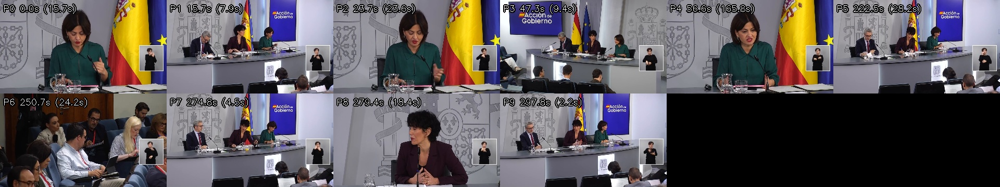

,plano,inicio_s,fin_s,duracion_s,revisar
0,0,0.000,15.733,15.733,False
1,1,15.733,23.667,7.934,False
2,2,23.667,47.267,23.600,False
3,3,47.267,56.633,9.366,False
4,4,56.633,222.467,165.834,False
5,5,222.467,250.667,28.200,False
6,6,250.667,274.833,24.166,False
7,7,274.833,279.367,4.534,False
8,8,279.367,297.767,18.400,False
9,9,297.767,300.000,2.233,False


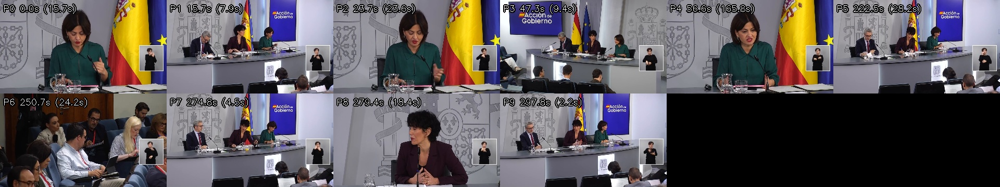

,plano,inicio_s,fin_s,duracion_s,revisar
0,0,0.000,15.733,15.733,False
1,1,15.733,23.667,7.934,False
2,2,23.667,47.267,23.600,False
3,3,47.267,56.633,9.366,False
4,4,56.633,222.467,165.834,False
5,5,222.467,250.667,28.200,False
6,6,250.667,274.833,24.166,False
7,7,274.833,279.367,4.534,False
8,8,279.367,297.767,18.400,False
9,9,297.767,300.000,2.233,False


In [11]:
# Mosaico: una miniatura por plano. En rojo, los planos a revisar.
from IPython.display import Image, display
display(Image(filename=str(SALIDA / "mosaico_planos.jpg")))
planos[["plano", "inicio_s", "fin_s", "duracion_s", "revisar"]]

**Qué comprobar:** ¿cada miniatura es una toma distinta? En una rueda de prensa esperaríamos planos de la persona que habla en el atril, planos generales de la sala y planos de periodistas.
- Dos miniaturas seguidas casi iguales → sobra un corte → sube `UMBRAL_CONTENT` en el Script 1.
- Un plano que mezcla dos tomas → falta un corte → bájalo (p. ej. 20).

## 3. Script 2 · Detección y seguimiento de personas

In [12]:
%run "{SCRIPT2}"

Librerías listas.
consejo_131026_1355s_300s.mp4: 1280x720, 30.00 fps, 300.0 s -> analizamos 1 de cada 3 (10.0 por segundo)
GPU: Tesla V100S-PCIE-32GB
Usando 10 planos de planos.csv
ByteTrack: {'track_high_thresh': 0.25, 'track_buffer': 20, 'match_thresh': 0.8}
  ... 60 s procesados (2091 detecciones)
  ... 120 s procesados (3273 detecciones)
  ... 180 s procesados (4445 detecciones)
  ... 240 s procesados (6352 detecciones)
10508 detecciones | 63 tracks de ByteTrack
74 tracks tras partir por plano | guardado /workspace/equipo5/NOA/resultados_v2/consejo_131026_1355s_300s/detecciones.csv
Tracks totales: 74 | fantasmas: 9 | válidos: 65 | de fondo (>50 % del tiempo): 6 | posibles imágenes: 14
Vídeo de revisión: /workspace/equipo5/NOA/resultados_v2/consejo_131026_1355s_300s/revision.mp4


In [13]:
# Vídeo de revisión (primeros 60 s). Verde = válido · gris = fondo · rojo = fantasma · morado = ¿foto/pantalla?
from IPython.display import Video
Video(str(SALIDA / "revision.mp4"), embed=True, width=800)

**Qué comprobar:**
- ¿La persona del atril mantiene **el mismo número** mientras habla? Si cambia mucho → sube `MEMORIA_TRACK_S` en el Script 2.
- ¿Salen **fantasmas** (rojo) en sitios donde no hay nadie? → sube `CONF_MIN`.
- En la sala de prensa habrá **periodistas pequeños al fondo** (gris): es lo esperado.
- Si hay **pantallas o fotos** detrás con personas, deberían salir en morado.

## 4. Primeras métricas de protagonismo (sin género ni audio todavía)

,plano,inicio_s,tiempo_pantalla_s,primer_plano_s,area_media_pct,centralidad_media
track_id,,,,,,
23_p4,4,56.7,165.7,165.7,33.57,0.95
2_p4,4,56.7,159.9,0.0,2.15,0.19
2_p5,5,222.5,28.2,0.0,2.11,0.19
27_p5,5,222.5,28.1,0.0,1.71,0.59
28_p5,5,222.5,28.1,0.0,3.83,0.35
26_p5,5,222.5,28.1,0.0,3.89,0.86
29_p5,5,223.5,26.3,0.0,3.11,0.77
39_p6,6,250.7,24.1,24.1,8.66,0.48
41_p6,6,250.7,24.1,2.9,7.07,0.61


Tiempo analizado: 300 s | con al menos una persona en pantalla: 300 s (100 %)
Personas (tracks) relevantes: 45 | en primer plano en algún momento: 13


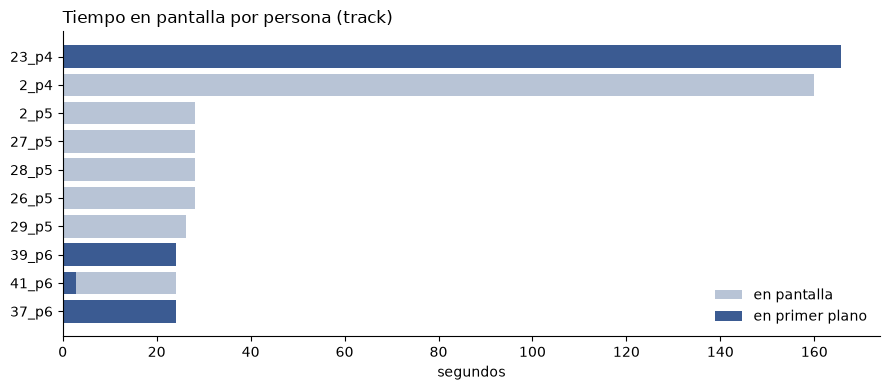

In [14]:
import matplotlib.pyplot as plt

PRIMER_PLANO_PCT = 8.0   # una persona que ocupa > 8 % de la pantalla la consideramos en primer plano

v = validos[(validos.pct_fondo <= 0.5) & (~validos.posible_imagen)].copy()
pp = det[det.area_pct > PRIMER_PLANO_PCT].groupby("track_id").frame_index.nunique() / FPS_ANALISIS
v["primer_plano_s"] = pp.reindex(v.index).fillna(0)

tabla = v[["plano", "inicio_s", "tiempo_pantalla_s", "primer_plano_s",
           "area_media_pct", "centralidad_media"]].sort_values("tiempo_pantalla_s", ascending=False)
display(tabla.round(2).head(15))

duracion = det.timestamp_s.max()
con_alguien = det.frame_index.nunique() / FPS_ANALISIS
print(f"Tiempo analizado: {duracion:.0f} s | con al menos una persona en pantalla: {con_alguien:.0f} s "
      f"({100 * con_alguien / max(duracion, 1):.0f} %)")
print(f"Personas (tracks) relevantes: {len(v)} | en primer plano en algún momento: {(v.primer_plano_s > 0).sum()}")

top = tabla.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.index, top.tiempo_pantalla_s, color="#B8C4D6", label="en pantalla")
ax.barh(top.index, top.primer_plano_s, color="#3B5B92", label="en primer plano")
ax.set_xlabel("segundos"); ax.set_title("Tiempo en pantalla por persona (track)", loc="left")
ax.legend(frameon=False); [ax.spines[s].set_visible(False) for s in ("top", "right")]
plt.tight_layout(); plt.show()

**Ojo al interpretar:** cada *track* es una aparición dentro de un plano, todavía **no una persona**. Si la portavoz sale en 10 planos distintos, aparecerá como 10 tracks.
Unirlos en una sola persona es el siguiente paso (caras con InsightFace o rótulos), igual que asignar género y cruzarlo con quién habla (audio).